# Chapter 3: Coherent Optical Imaging in Semiconductor Lithography

## 3.1 Introduction

In the previous chapter, the propagation of light through a single-slit photomask was investigated using the Angular Spectrum Method (ASM). The numerical simulations demonstrated how diffraction modifies the spatial distribution of an optical field as it propagates through free space.

However, modern optical lithography does not rely solely on free-space propagation. Instead, optical projection systems are used to form an image of the photomask onto a photoresist-coated semiconductor wafer.

The quality of the projected image depends on the ability of the optical system to transmit the spatial-frequency components generated by the photomask.

According to Fourier optics, an optical imaging system can be interpreted as a spatial-frequency filtering system. The finite aperture of the projection optics limits the range of spatial frequencies that contribute to image formation.

### 3.1.1 Numerical Aperture and Spatial Resolution

The numerical aperture (NA) characterizes the angular acceptance of an optical system and is defined as:

$$
\mathrm{NA}=n\sin\alpha
$$

where $n$ is the refractive index of the image-space medium and $\alpha$ is the maximum accepted angle relative to the optical axis.

For an ideal coherent imaging system, the maximum transmitted transverse spatial frequency is:

$$
\boxed{f_{\max}=\frac{\mathrm{NA}}{\lambda}}
$$

Spatial-frequency components exceeding this cutoff cannot propagate through the idealized imaging pupil.

Consequently, fine structures containing high spatial frequencies may be blurred or lost during image formation.

Increasing the numerical aperture allows the imaging system to transmit additional spatial-frequency components, potentially improving the reproduction of the photomask pattern.

### 3.1.2 Mathematical Model of Coherent Imaging

We consider a one-dimensional periodic binary photomask with a pitch of:

$$
p=4\,\mu\mathrm{m}
$$

and a duty cycle of 50%, corresponding to transparent and opaque regions of equal width.

The wavelength of the incident monochromatic light is:

$$
\lambda=500\,\mathrm{nm}
$$

The photomask transmission function is represented by $M(x)$.

Under coherent illumination, the optical image is calculated by filtering the Fourier spectrum of the photomask using the pupil function:

$$
P(f_x)=
\begin{cases}
1, & |f_x|\leq\frac{\mathrm{NA}}{\lambda}\\
0, & |f_x|>\frac{\mathrm{NA}}{\lambda}
\end{cases}
$$

The complex amplitude of the reconstructed optical field is:

$$
\boxed{
U_{\mathrm{image}}(x)=
\mathcal{F}^{-1}
\left\{
\mathcal{F}[M(x)]P(f_x)
\right\}
}
$$

The corresponding aerial-image intensity is:

$$
\boxed{I_{\mathrm{image}}(x)=|U_{\mathrm{image}}(x)|^2}
$$

This formulation describes an ideal coherent imaging system with unit magnification. Optical aberrations, defocus, and partial coherence are neglected.

### 3.1.3 Objectives of the Numerical Simulation

The main objective of this chapter is to investigate how numerical aperture influences optical image formation and the reproduction of microscopic patterns.

Three numerical apertures are considered:

- NA = 0.08
- NA = 0.18
- NA = 0.45

The numerical analysis includes:

1. Reconstruction of the periodic photomask pattern using the Fast Fourier Transform (FFT).
2. Investigation of the influence of numerical aperture on the aerial-image intensity distribution.
3. Calculation of Michelson image contrast.
4. Evaluation of image reconstruction fidelity using Root Mean Square Error (RMSE).
5. Estimation of critical dimensions (CD) using an intensity-threshold method.
6. Investigation of critical-dimension sensitivity to the selected intensity threshold.

By comparing these results, we aim to understand the relationship between spatial-frequency filtering, numerical aperture, and image quality in semiconductor lithography.

The resulting aerial images provide the optical foundation for the photoresist exposure and pattern-transfer simulations developed in Chapter 4.

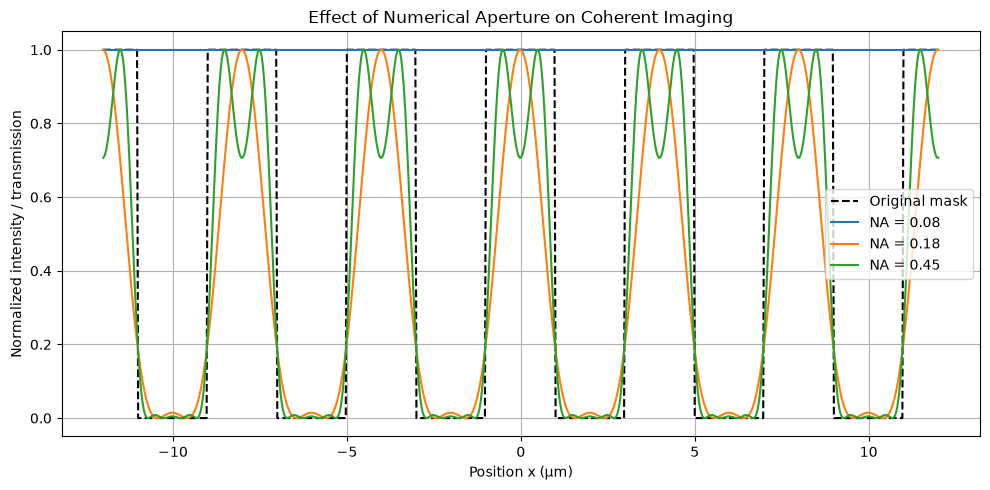

In [4]:

import numpy as np
import matplotlib.pyplot as plt

# Physical and numerical parameters
wavelength = 500e-9
pitch = 4e-6

N = 4096
Lx = 128e-6
dx = Lx / N

x = (np.arange(N) - N//2) * dx

# Periodic binary photomask, 50% duty cycle
M = period_pixels = int(round(pitch / dx))
indices = np.arange(N) - N // 2

M = (
    (indices + period_pixels // 4) % period_pixels
    < period_pixels // 2
).astype(float)

# Spatial frequencies (cycles/m)
fx = np.fft.fftfreq(N, d=dx)
mask_spectrum = np.fft.fft(M)

# Ideal coherent imaging at unit magnification
NA_values = [0.08, 0.18, 0.45]

region = np.abs(x) <= 12e-6

plt.figure(figsize=(10, 5))
plt.plot(x[region]*1e6, M[region],
         "k--", label="Original mask")

for NA in NA_values:
    pupil = (np.abs(fx) <= NA/wavelength).astype(float)

    U_image = np.fft.ifft(mask_spectrum * pupil)
    intensity = np.abs(U_image)**2
    intensity /= intensity.max()

    plt.plot(x[region]*1e6, intensity[region],
             label=f"NA = {NA}")

plt.xlabel("Position x (µm)")
plt.ylabel("Normalized intensity / transmission")
plt.title("Effect of Numerical Aperture on Coherent Imaging")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


NA = 0.08 | Contrast = 0.00000
NA = 0.18 | Contrast = 0.99999
NA = 0.45 | Contrast = 1.00000


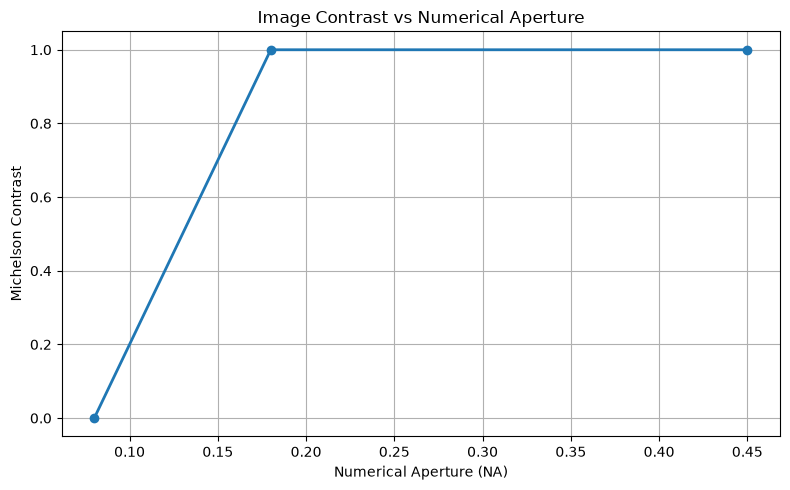

In [5]:

# Michelson contrast calculation

contrast_values = []

for NA in NA_values:
    pupil = (np.abs(fx) <= NA / wavelength).astype(float)

    U_image = np.fft.ifft(mask_spectrum * pupil)
    I = np.abs(U_image)**2

    I_max = I.max()
    I_min = I.min()

    contrast = (I_max - I_min) / (I_max + I_min)
    contrast_values.append(contrast)

    print(f"NA = {NA:.2f} | Contrast = {contrast:.5f}")

plt.figure(figsize=(8, 5))
plt.plot(NA_values, contrast_values, "o-", linewidth=2)

plt.xlabel("Numerical Aperture (NA)")
plt.ylabel("Michelson Contrast")
plt.title("Image Contrast vs Numerical Aperture")
plt.ylim(-0.05, 1.05)
plt.grid(True)
plt.tight_layout()
plt.show()



### 3.3 Image Contrast Analysis

The Michelson contrast was calculated to quantify the visibility of the periodic photomask pattern after coherent optical imaging.

The contrast is defined as:

$$
C=\frac{I_{\max}-I_{\min}}{I_{\max}+I_{\min}}
$$

The numerical results are:

| Numerical Aperture | Michelson Contrast |
|---|---|
| 0.08 | 0.00000 |
| 0.18 | 0.99999 |
| 0.45 | 1.00000 |

For NA = 0.08, only the zero diffraction order is transmitted, resulting in a uniform intensity distribution and zero image contrast.

For NA = 0.18, the first diffraction orders are transmitted, enabling the reconstruction of the periodic structure with nearly maximum contrast.

Increasing NA to 0.45 allows additional spatial harmonics to pass through the optical system, improving the reproduction of sharp transitions.

For a periodic photomask, the diffraction order $m$ is transmitted when:

$$
\mathrm{NA}\geq\frac{|m|\lambda}{p}
$$

The first and third diffraction orders correspond to critical numerical apertures of 0.125 and 0.375, respectively.

Although the Michelson contrast reaches nearly unity, this does not imply perfect image reconstruction.

Image contrast alone cannot fully characterize edge sharpness, spatial distortions, or the fidelity of the transferred pattern.


NA = 0.08 | Image RMSE = 0.707107
NA = 0.18 | Image RMSE = 0.303838
NA = 0.45 | Image RMSE = 0.225791


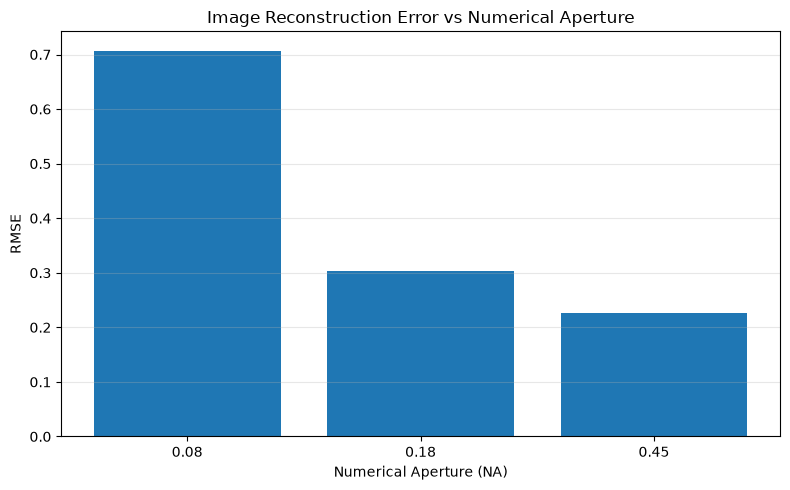

In [6]:

# Image fidelity analysis using RMSE

rmse_values = []

for NA in NA_values:

    # Coherent optical pupil
    pupil = (np.abs(fx) <= NA / wavelength).astype(float)

    # Reconstructed optical field
    U_image = np.fft.ifft(mask_spectrum * pupil)

    # Normalized image intensity
    I_image = np.abs(U_image)**2
    I_image /= I_image.max()

    # Comparison with ideal binary mask intensity
    rmse = np.sqrt(np.mean((I_image - M)**2))
    rmse_values.append(rmse)

    print(f"NA = {NA:.2f} | Image RMSE = {rmse:.6f}")

# Plot image reconstruction error
plt.figure(figsize=(8, 5))

plt.bar(
    [f"{NA:.2f}" for NA in NA_values],
    rmse_values
)

plt.xlabel("Numerical Aperture (NA)")
plt.ylabel("RMSE")
plt.title("Image Reconstruction Error vs Numerical Aperture")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()



### 3.4 Image Fidelity and Reconstruction Error

The fidelity of the reconstructed optical image was evaluated using the Root Mean Square Error (RMSE) between the normalized aerial-image intensity and the ideal binary mask intensity.

The error metric is defined as:

$$
\mathrm{RMSE} =
\sqrt{
\frac{1}{N}
\sum_{j=1}^{N}
\left[I_{\mathrm{image}}(x_j)-M(x_j)\right]^2
}
$$

The numerical results were:

| Numerical Aperture | Image RMSE |
|---|---|
| 0.08 | 0.707107 |
| 0.18 | 0.303838 |
| 0.45 | 0.225791 |

Increasing the numerical aperture from 0.08 to 0.45 significantly improves the reconstruction fidelity.

Although the images obtained at NA = 0.18 and NA = 0.45 exhibit nearly identical Michelson contrast, the latter produces a lower reconstruction error.

This demonstrates that image contrast and reconstruction fidelity characterize different aspects of optical imaging.

The RMSE is a numerical measure of agreement with the chosen reference mask. It does not directly represent the final dimensions of a photoresist pattern.

A more lithographically relevant analysis requires the evaluation of critical dimensions and intensity thresholds.


In [7]:

# Critical Dimension (CD) analysis
# Simplified intensity-threshold model

threshold = 0.5
ideal_CD = pitch / 2

for NA in NA_values:

    pupil = (np.abs(fx) <= NA / wavelength).astype(float)

    U_image = np.fft.ifft(mask_spectrum * pupil)
    I = np.abs(U_image)**2
    I /= I.max()

    # Select the central period
    selected = np.abs(x) <= pitch / 2
    xx = x[selected]
    yy = I[selected]

    # Find threshold crossings using linear interpolation
    crossings = []

    for j in range(len(xx) - 1):
        if (yy[j] - threshold) * (yy[j+1] - threshold) < 0:

            crossing = xx[j] + (
                (threshold - yy[j])
                * (xx[j+1] - xx[j])
                / (yy[j+1] - yy[j])
            )

            crossings.append(crossing)

    left = [v for v in crossings if v < 0]
    right = [v for v in crossings if v > 0]

    if not left or not right:
        print(f"NA = {NA:.2f}: No resolved CD")
        continue

    x_left = max(left)
    x_right = min(right)

    CD = x_right - x_left

    print(
        f"NA = {NA:.2f} | "
        f"CD = {CD*1e6:.4f} µm | "
        f"Ideal CD = {ideal_CD*1e6:.4f} µm"
    )


NA = 0.08: No resolved CD
NA = 0.18 | CD = 1.3671 µm | Ideal CD = 2.0000 µm
NA = 0.45 | CD = 1.7102 µm | Ideal CD = 2.0000 µm



### 3.6 Critical Dimension Results and Analysis

The Critical Dimension (CD) was evaluated using a normalized aerial-image intensity threshold of 0.5.

The ideal transparent line width of the photomask is:

$$
CD_{\mathrm{ideal}}=\frac{p}{2}=2\,\mu\mathrm{m}
$$

The relative CD error is defined as:

$$
\epsilon_{CD}=
\frac{|CD_{\mathrm{measured}}-CD_{\mathrm{ideal}}|}
{CD_{\mathrm{ideal}}}\times100\%
$$

The numerical results are summarized below:

| NA | Measured CD (µm) | Relative Error |
|---|---|---|
| 0.08 | Not resolved | — |
| 0.18 | 1.3671 | 31.65% |
| 0.45 | 1.7102 | 14.49% |

For NA = 0.08, the optical system does not resolve the periodic pattern, and no meaningful CD can be extracted.

At NA = 0.18, the measured CD is significantly smaller than the ideal mask dimension.

Increasing NA to 0.45 improves the reconstruction of the line width and reduces the relative CD error.

These results demonstrate the importance of the numerical aperture in coherent lithographic imaging.

However, the measured CD depends on the selected intensity threshold. Therefore, a threshold sensitivity analysis is required before drawing conclusions about lithographic pattern transfer.


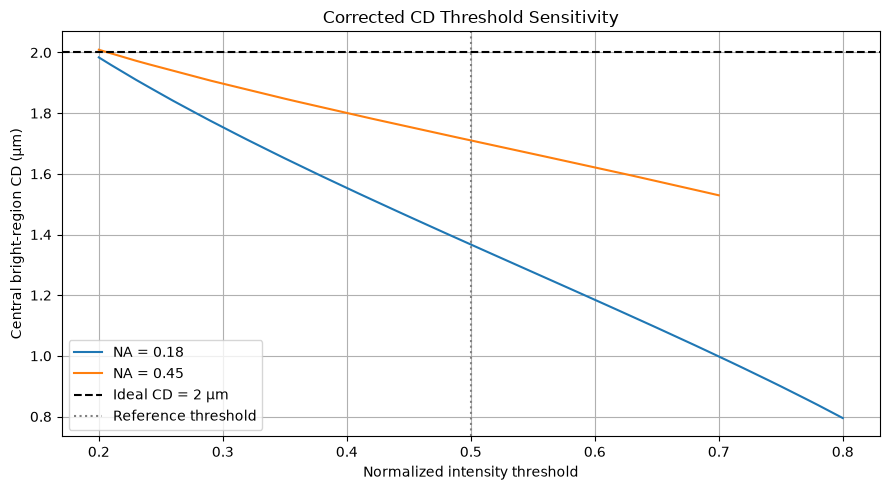

In [9]:

# Corrected Threshold Sensitivity Analysis

thresholds = np.linspace(0.2, 0.8, 61)

plt.figure(figsize=(9, 5))

for NA in [0.18, 0.45]:

    pupil = (np.abs(fx) <= NA / wavelength).astype(float)

    U_image = np.fft.ifft(mask_spectrum * pupil)
    I = np.abs(U_image)**2
    I /= I.max()

    selected = np.abs(x) <= pitch / 2
    xx = x[selected]
    yy = I[selected]

    center = np.argmin(np.abs(xx))
    CD_values = []

    for threshold in thresholds:

        # The central feature must remain above threshold
        if yy[center] <= threshold:
            CD_values.append(np.nan)
            continue

        # Find the connected bright region around x = 0
        left = center
        while left > 0 and yy[left - 1] >= threshold:
            left -= 1

        right = center
        while right < len(yy)-1 and yy[right + 1] >= threshold:
            right += 1

        if left == 0 or right == len(yy)-1:
            CD_values.append(np.nan)
            continue

        # Linear interpolation of the two outer crossings
        x_left = xx[left-1] + (
            (threshold - yy[left-1])
            * (xx[left] - xx[left-1])
            / (yy[left] - yy[left-1])
        )

        x_right = xx[right] + (
            (threshold - yy[right])
            * (xx[right+1] - xx[right])
            / (yy[right+1] - yy[right])
        )

        CD_values.append((x_right-x_left)*1e6)

    plt.plot(thresholds, CD_values, label=f"NA = {NA}")

plt.axhline(2.0, color="black", linestyle="--",
            label="Ideal CD = 2 µm")
plt.axvline(0.5, color="gray", linestyle=":",
            label="Reference threshold")

plt.xlabel("Normalized intensity threshold")
plt.ylabel("Central bright-region CD (µm)")
plt.title("Corrected CD Threshold Sensitivity")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
